<a href="https://colab.research.google.com/github/naulla/pm-turi4-clustering/blob/main/PM_P9_Naula_Alfiyatul_Fauziyyah_2488010063.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**C. Langkah Praktikum**

Langkah 1 — Menyiapkan data & scaling (wajib).

In [5]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# df berisi usia, pendapatan, skor_belanja (tanpa label)
df = pd.DataFrame({
    'usia': [
        23, 45, 31, 52, 27, 38, 19, 61, 34, 48,
        25, 56, 42, 30, 65, 37, 21, 50, 44, 29
    ],

    'pendapatan': [
        4500, 12000, 6500, 15000, 3800, 8500, 3200, 11000, 7200, 13500,
        5000, 9000, 10500, 4200, 14500, 7800, 3500, 12500, 9500, 6000
    ],

    'skor_belanja': [
        78, 35, 62, 20, 88, 45, 92, 15, 70, 28,
        83, 40, 55, 75, 12, 58, 95, 32, 48, 81
    ]
})

X_scaled = StandardScaler().fit_transform(df)

Langkah 2 — Metode Elbow menentukan K.

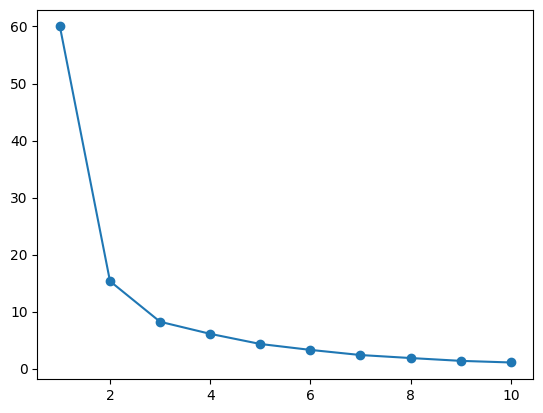

In [2]:
from sklearn.cluster import KMeans
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)
plt.plot(range(1,11), inertias, marker='o'); plt.show()


Langkah 3 — Menjalankan K-Means (K=3).

In [6]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())

cluster
1    7
0    7
2    6
Name: count, dtype: int64


Langkah 4 — Evaluasi silhouette score.

In [7]:
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df['cluster']))

0.49324228174472806


Langkah 5 — Interpretasi: profil rata-rata tiap cluster.

In [8]:
profil = df.groupby('cluster')[['usia', 'pendapatan',
                                'skor_belanja']].mean().round(1)

print("Profil Rata-rata Tiap Cluster:")
print(profil)

for cluster, data in profil.iterrows():
    print(f"\nCluster {cluster}:")

    if data['skor_belanja'] >= 50:
        kategori_belanja = "Skor belanja tinggi"
    elif data['skor_belanja'] >= 30:
        kategori_belanja = "Skor belanja sedang"
    else:
        kategori_belanja = "Skor belanja rendah"

    print(f"Rata-rata usia         : {data['usia']} tahun")
    print(f"Rata-rata pendapatan   : {data['pendapatan']}")
    print(f"Rata-rata skor belanja : {data['skor_belanja']}")
    print(f"Interpretasi           : {kategori_belanja}")

Profil Rata-rata Tiap Cluster:
         usia  pendapatan  skor_belanja
cluster                                
0        53.9     12500.0          26.0
1        24.9      4314.3          84.6
2        37.7      8333.3          56.3

Cluster 0:
Rata-rata usia         : 53.9 tahun
Rata-rata pendapatan   : 12500.0
Rata-rata skor belanja : 26.0
Interpretasi           : Skor belanja rendah

Cluster 1:
Rata-rata usia         : 24.9 tahun
Rata-rata pendapatan   : 4314.3
Rata-rata skor belanja : 84.6
Interpretasi           : Skor belanja tinggi

Cluster 2:
Rata-rata usia         : 37.7 tahun
Rata-rata pendapatan   : 8333.3
Rata-rata skor belanja : 56.3
Interpretasi           : Skor belanja tinggi


**D. Latihan Mandiri**

6. Jalankan K-Means K=5; bandingkan silhouette score dengan K=3.

Jawaban:

In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# K = 3
kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_3 = kmeans_3.fit_predict(X_scaled)
silhouette_3 = silhouette_score(X_scaled, cluster_3)

# K = 5
kmeans_5 = KMeans(n_clusters=5, random_state=42, n_init=10)
cluster_5 = kmeans_5.fit_predict(X_scaled)
silhouette_5 = silhouette_score(X_scaled, cluster_5)

print("Silhouette Score K=3:", round(silhouette_3, 3))
print("Silhouette Score K=5:", round(silhouette_5, 3))

if silhouette_5 > silhouette_3:
    print("Kesimpulan: K=5 memiliki kualitas clustering lebih baik.")
elif silhouette_5 < silhouette_3:
    print("Kesimpulan: K=3 memiliki kualitas clustering lebih baik.")
else:
    print("Kesimpulan: Kedua nilai Silhouette Score sama.")

Silhouette Score K=3: 0.493
Silhouette Score K=5: 0.407
Kesimpulan: K=3 memiliki kualitas clustering lebih baik.


7. Jalankan K-Means tanpa scaling (K=3); bandingkan silhouette-nya. Apa kesimpulannya?

Jawaban:

In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans_raw = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_raw = kmeans_raw.fit_predict(df[['usia', 'pendapatan', 'skor_belanja']])

silhouette_raw = silhouette_score(
    df[['usia', 'pendapatan', 'skor_belanja']],
    cluster_raw
)

print("Silhouette Score dengan scaling:", round(silhouette_3, 3))
print("Silhouette Score tanpa scaling:", round(silhouette_raw, 3))

Silhouette Score dengan scaling: 0.493
Silhouette Score tanpa scaling: 0.567


8. Buat scatter plot cluster pada fitur usia (x) vs skor_belanja (y).
teks yang dimiringkan

Jawaban:

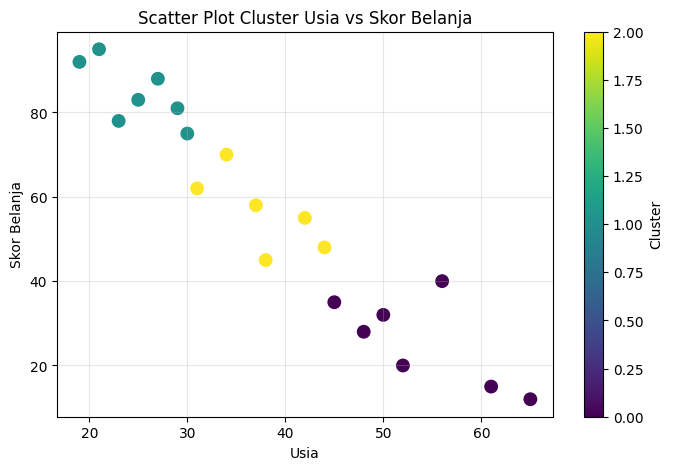

In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['usia'],
    df['skor_belanja'],
    c=df['cluster'],
    cmap='viridis',
    s=80
)

plt.xlabel('Usia')
plt.ylabel('Skor Belanja')
plt.title('Scatter Plot Cluster Usia vs Skor Belanja')
plt.colorbar(label='Cluster')
plt.grid(True, alpha=0.3)
plt.show()

**E. Refleksi**

9. Bagaimana K-Means menemukan kelompok tanpa label?

Jawaban:
K-Means mengelompokkan data berdasarkan kemiripan usia, pendapatan, dan skor belanja. Data dengan jarak yang berdekatan akan masuk ke kelompok yang sama. Proses ini akan dilakukan sampai posisi pusat kelompok stabil.

10. Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?

Jawaban:
Karena pada K = 3, penurunan nilai inertia mulai melambat. Hal ini terjadi karena data sudah mulai terbagi ke kelompok yang sesuai, sehingga penurunan nilai inertia setelahnya tidak sebesar sebelumnya.

11. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?

Jawaban:
Scaling penting karena nilai usia, pendapatan, dan skor belanja memiliki rentang yang berbeda. Dengan scaling, ketiga fitur memiliki skala yang lebih seimbang. Jika tidak menggunakan scaling, pendapatan bisa lebih mendominasi perhitungan jarak karena nilainya jauh lebih besar dibandingkan fitur lainnya. Akibatnya, hasil clustering bisa lebih banyak dipengaruhi oleh pendapatan daripada usia dan skor belanja.